# Group by

In [4]:
import pandas as pd
import numpy as np

## 1. Splitting an object into groups 

In [5]:
df = pd.DataFrame(
     [
     ("bird", "Falconiformes", 389.0),
     ("bird", "Psittaciformes", 24.0),
     ("mammal", "Carnivora", 80.2),
     ("mammal", "Primates", np.nan),
     ("mammal", "Carnivora", 58),
     ],
     index=["falcon", "parrot", "lion", "monkey", "leopard"],
     columns=("class", "order", "max_speed"),
     )


In [6]:
df

,class,order,max_speed
falcon,bird,Falconiformes,389.0
parrot,bird,Psittaciformes,24.0
lion,mammal,Carnivora,80.2
monkey,mammal,Primates,NaN
leopard,mammal,Carnivora,58.0


In [7]:
# default is axis=0 
grouped = df.groupby("class")

In [8]:
grouped = df.groupby("order", axis="columns")

C:\Users\Lenova\AppData\Local\Temp\ipykernel_16856\407435193.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  grouped = df.groupby("order", axis="columns")


In [9]:
grouped = df.groupby(["class", "order"])

<b>NOTE: </b><i>A string passed to groupby may refer to either a column or an index level. If a string matches both a column
name and an index level name, a ValueError will be raised</i>

In [10]:
df = pd.DataFrame(
     {
     "A": ["foo", "bar", "foo", "bar", "foo", "bar", "foo", "foo"],
     "B": ["one", "one", "two", "three", "two", "two", "one", "three"],
     "C": np.random.randn(8),
     "D": np.random.randn(8),
     }
     )
df

,A,B,C,D
0,foo,one,-1.693512,-1.689078
1,bar,one,0.556509,-0.616141
2,foo,two,-0.500910,-0.180705
3,bar,three,0.384107,-1.310416
4,foo,two,-0.547198,0.880851
5,bar,two,-0.505415,0.201297
6,foo,one,0.241076,-0.827748
7,foo,three,2.281170,-0.232067


In [11]:
grouped = df.groupby("A")

In [12]:
grouped = df.groupby(["A", "B"])

In [13]:
# MultiIndex on columns A and B
df2 = df.set_index(["A", "B"])
grouped = df2.groupby(level=df2.index.names.difference(["B"]))
grouped.sum()

,C,D
A,,
bar,0.435200,-1.725260
foo,-0.219374,-2.048747


In [14]:
#We could also split by the columns:
def get_letter_type(letter):
    if letter.lower() in 'aeiou':
         return 'vowel'
    else:
         return 'consonant'

In [15]:
grouped = df.groupby(get_letter_type, axis=1)

C:\Users\Lenova\AppData\Local\Temp\ipykernel_16856\4082038865.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  grouped = df.groupby(get_letter_type, axis=1)


In [16]:
lst = [1, 2, 3, 1, 2, 3]
s = pd.Series([1, 2, 3, 10, 20, 30], lst)
s


1     1
2     2
3     3
1    10
2    20
3    30
dtype: int64

In [17]:
grouped = s.groupby(level=0)
grouped.first()

1    1
2    2
3    3
dtype: int64

In [18]:
grouped.last()

1    10
2    20
3    30
dtype: int64

In [19]:
grouped.sum()

1    11
2    22
3    33
dtype: int64

### 1.1. GroupBy sorting 

In [20]:
df2 = pd.DataFrame({"X": ["B", "B", "A", "A"], "Y": [1, 2, 3, 4]})
df2.groupby(["X"]).sum()

,Y
X,
A,7
B,3


In [21]:
df2.groupby(["X"], sort=False).sum()

,Y
X,
B,3
A,7


In [22]:
df3 = pd.DataFrame({"X": ["A", "B", "A", "B"], "Y": [1, 4, 3, 2]})
df3.groupby(["X"]).get_group("A")

C:\Users\Lenova\AppData\Local\Temp\ipykernel_16856\2662534176.py:2: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  df3.groupby(["X"]).get_group("A")


,X,Y
0,A,1
2,A,3


In [23]:
df3.groupby(["X"]).get_group("B")

C:\Users\Lenova\AppData\Local\Temp\ipykernel_16856\862706516.py:1: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  df3.groupby(["X"]).get_group("B")


,X,Y
1,B,4
3,B,2


### 1.2. GroupBy dropna 

In [24]:
df_list = [[1, 2, 3], [1, None, 4], [2, 1, 3], [1, 2, 2]]
df_dropna = pd.DataFrame(df_list, columns=["a", "b", "c"])
df_dropna

,a,b,c
0,1,2.0,3
1,1,NaN,4
2,2,1.0,3
3,1,2.0,2


In [25]:
# Default "dropna" is set to True, which will exclude NaNs in keys
df_dropna.groupby(by=["b"], dropna=True).sum()


,a,c
b,,
1.0,2,3
2.0,2,5


In [26]:
# In order to allow NaN in keys, set ``dropna`` to False
df_dropna.groupby(by=["b"], dropna=False).sum()

,a,c
b,,
1.0,2,3
2.0,2,5
NaN,1,4


### 1.3. GroupBy object attributes 

In [27]:
df.groupby("A").groups

{'bar': [1, 3, 5], 'foo': [0, 2, 4, 6, 7]}

In [28]:
df.groupby(get_letter_type, axis=1).groups

C:\Users\Lenova\AppData\Local\Temp\ipykernel_16856\2800522858.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df.groupby(get_letter_type, axis=1).groups


{'consonant': ['B', 'C', 'D'], 'vowel': ['A']}

In [29]:
grouped = df.groupby(["A", "B"])
grouped.groups

{('bar', 'one'): [1], ('bar', 'three'): [3], ('bar', 'two'): [5], ('foo', 'one'): [0, 6], ('foo', 'three'): [7], ('foo', 'two'): [2, 4]}

In [30]:
len(grouped)

6

In [31]:
df = pd.DataFrame(
     {
     "height": [42.8,49.6,56.2, 48.4,46.5,68.5,70.1,58.9,76.4,45.3],
     "weight": [ 157.500553,177.340407,171.524640, 144.251986,152.526206,168.272968,136.431469,176.499753,174.094104, 177.540920],
     "gender": ["male","male","male","female","male","female","male","female","female","male"]
     },
     index=["2000-01-01","2000-01-02","2000-01-03","2000-01-04","2000-01-05","2000-01-06","2000-01-07","2000-01-08","2000-01-09","2000-01-10"]
     )
df

,height,weight,gender
2000-01-01,42.8,157.500553,male
2000-01-02,49.6,177.340407,male
2000-01-03,56.2,171.524640,male
2000-01-04,48.4,144.251986,female
2000-01-05,46.5,152.526206,male
2000-01-06,68.5,168.272968,female
2000-01-07,70.1,136.431469,male
2000-01-08,58.9,176.499753,female
2000-01-09,76.4,174.094104,female
2000-01-10,45.3,177.540920,male


In [32]:
gb = df.groupby("gender")

In [33]:
gb.max()

,height,weight
gender,,
female,76.4,176.499753
male,70.1,177.540920


In [34]:
arrays = [
     ["bar", "bar", "baz", "baz", "foo", "foo", "qux", "qux"],
     ["one", "two", "one", "two", "one", "two", "one", "two"],
     ]


In [35]:
index = pd.MultiIndex.from_arrays(arrays, names=["first", "second"])
s = pd.Series(np.random.randn(8), index=index)

In [36]:
s

first  second
bar    one       0.302979
       two       0.447058
baz    one       1.015574
       two       1.007770
foo    one       0.583575
       two      -0.042965
qux    one       1.913440
       two       0.781658
dtype: float64

In [37]:
grouped = s.groupby(level=0)

In [38]:
grouped.sum()

first
bar    0.750036
baz    2.023343
foo    0.540610
qux    2.695098
dtype: float64

In [39]:
s.groupby(level="second").sum()

second
one    3.815568
two    2.193520
dtype: float64

In [137]:
s.groupby(level="second").sum()

second
one   -3.055124
two    0.722018
dtype: float64

In [138]:
s

first  second
bar    one      -2.706653
       two       0.175048
baz    one      -0.946487
       two       0.725778
foo    one      -0.982982
       two      -0.930571
qux    one       1.580998
       two       0.751762
dtype: float64

In [139]:
s.groupby(level=[ "second"]).sum()

second
one   -3.055124
two    0.722018
dtype: float64

In [140]:
s.groupby(["first"]).sum()

first
bar   -2.531605
baz   -0.220709
foo   -1.913553
qux    2.332760
dtype: float64

### 1.4. Grouping DataFrame with Index levels and columns 

In [141]:
arrays = [
     ["bar", "bar", "baz", "baz", "foo", "foo", "qux", "qux"],
     ["one", "two", "one", "two", "one", "two", "one", "two"],
     ]
index = pd.MultiIndex.from_arrays(arrays, names=["first", "second"])
df = pd.DataFrame({"A": [1, 1, 1, 1, 2, 2, 3, 3], "B": np.arange(8)},index=index)

In [142]:
df

A  B
first second      
bar   one     1  0
      two     1  1
baz   one     1  2
      two     1  3
foo   one     2  4
      two     2  5
qux   one     3  6
      two     3  7

In [143]:
df.groupby([pd.Grouper(level=1), "A"]).sum()


B
second A   
one    1  2
       2  4
       3  6
two    1  4
       2  5
       3  7

In [144]:
df.groupby([pd.Grouper(level="second"), "A"]).sum()

B
second A   
one    1  2
       2  4
       3  6
two    1  4
       2  5
       3  7

In [145]:
df.groupby(["second", "A"]).sum()


B
second A   
one    1  2
       2  4
       3  6
two    1  4
       2  5
       3  7

### 1.5. DataFrame column selection in GroupBy 

In [146]:
df = pd.DataFrame(
     {
     "A": ["foo", "bar", "foo", "bar", "foo", "bar", "foo", "foo"],
     "B": ["one", "one", "two", "three", "two", "two", "one", "three"],
     "C": np.random.randn(8),
     "D": np.random.randn(8),
     }
     )
df

,A,B,C,D
0,foo,one,-0.502286,1.152665
1,bar,one,1.887845,-2.055050
2,foo,two,-0.590231,0.592425
3,bar,three,-0.273278,-1.623022
4,foo,two,-0.699919,-0.733953
5,bar,two,1.111050,-2.028594
6,foo,one,0.581125,-0.516107
7,foo,three,0.033661,-1.921318


In [147]:
grouped = df.groupby(["A"])
grouped_C = grouped["C"]
grouped_D = grouped["D"]

In [148]:
 df["C"].groupby(df["A"])

### 2. Iterating through groups 

In [149]:
grouped = df.groupby('A')

In [150]:
for name, group in grouped:
    print(name)
    print(group)

bar
     A      B         C         D
1  bar    one  1.887845 -2.055050
3  bar  three -0.273278 -1.623022
5  bar    two  1.111050 -2.028594
foo
     A      B         C         D
0  foo    one -0.502286  1.152665
2  foo    two -0.590231  0.592425
4  foo    two -0.699919 -0.733953
6  foo    one  0.581125 -0.516107
7  foo  three  0.033661 -1.921318


In [151]:
for name, group in df.groupby(['A', 'B']):
        print(name)
        print(group)

('bar', 'one')
     A    B         C        D
1  bar  one  1.887845 -2.05505
('bar', 'three')
     A      B         C         D
3  bar  three -0.273278 -1.623022
('bar', 'two')
     A    B        C         D
5  bar  two  1.11105 -2.028594
('foo', 'one')
     A    B         C         D
0  foo  one -0.502286  1.152665
6  foo  one  0.581125 -0.516107
('foo', 'three')
     A      B         C         D
7  foo  three  0.033661 -1.921318
('foo', 'two')
     A    B         C         D
2  foo  two -0.590231  0.592425
4  foo  two -0.699919 -0.733953


## 3. Selecting a group

In [152]:
grouped.get_group("bar")

,A,B,C,D
1,bar,one,1.887845,-2.055050
3,bar,three,-0.273278,-1.623022
5,bar,two,1.111050,-2.028594


In [153]:
df.groupby(["A", "B"]).get_group(("bar", "one"))

,A,B,C,D
1,bar,one,1.887845,-2.05505


## 4. Transformation  

In [154]:
index = pd.date_range("10/1/1999", periods=1100)
ts = pd.Series(np.random.normal(0.5, 2, 1100), index)
ts = ts.rolling(window=100, min_periods=100).mean().dropna()

In [155]:
ts.head()

2000-01-08    0.509560
2000-01-09    0.520356
2000-01-10    0.508168
2000-01-11    0.563011
2000-01-12    0.569920
Freq: D, dtype: float64

In [156]:
ts.tail()

2002-09-30    0.417021
2002-10-01    0.486315
2002-10-02    0.497550
2002-10-03    0.506551
2002-10-04    0.532067
Freq: D, dtype: float64

In [157]:
transformed = ts.groupby(lambda x: x.year).transform(
     lambda x: (x - x.mean()) / x.std()
     )

In [158]:
# Original Data
grouped = ts.groupby(lambda x: x.year)

In [159]:
grouped.mean()

2000    0.532064
2001    0.457018
2002    0.468387
dtype: float64

In [160]:
grouped.std()

2000    0.152274
2001    0.110660
2002    0.192071
dtype: float64

In [161]:
# Transformed Data
grouped_trans = transformed.groupby(lambda x: x.year)

In [162]:
grouped_trans.mean()

2000   -1.712496e-16
2001    3.020415e-16
2002    2.599204e-16
dtype: float64

In [163]:
grouped_trans.std()

2000    1.0
2001    1.0
2002    1.0
dtype: float64

<Axes: >

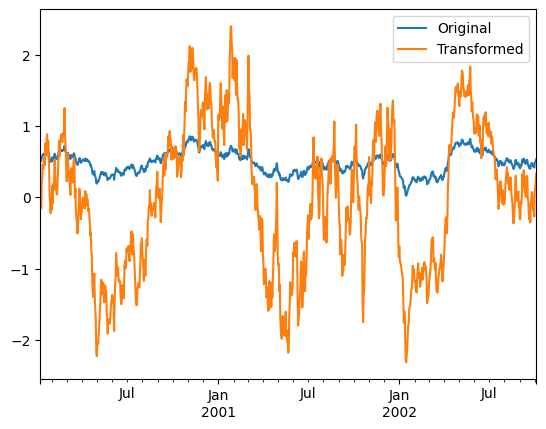

In [164]:
compare = pd.DataFrame({"Original": ts, "Transformed": transformed})
compare.plot()

In [165]:
ts.groupby(lambda x: x.year).transform(lambda x: x.max() - x.min())

2000-01-08    0.661983
2000-01-09    0.661983
2000-01-10    0.661983
2000-01-11    0.661983
2000-01-12    0.661983
                ...   
2002-09-30    0.796067
2002-10-01    0.796067
2002-10-02    0.796067
2002-10-03    0.796067
2002-10-04    0.796067
Freq: D, Length: 1001, dtype: float64

In [166]:
max = ts.groupby(lambda x: x.year).transform("max")
min = ts.groupby(lambda x: x.year).transform("min")
max - min

2000-01-08    0.661983
2000-01-09    0.661983
2000-01-10    0.661983
2000-01-11    0.661983
2000-01-12    0.661983
                ...   
2002-09-30    0.796067
2002-10-01    0.796067
2002-10-02    0.796067
2002-10-03    0.796067
2002-10-04    0.796067
Freq: D, Length: 1001, dtype: float64

## 5. Filtration 

In [167]:
sf = pd.Series([1, 1, 2, 3, 3, 3])

In [168]:
sf.groupby(sf).filter(lambda x: x.sum() > 2)

3    3
4    3
5    3
dtype: int64

In [169]:
dff = pd.DataFrame({"A": np.arange(8), "B": list("aabbbbcc")})

In [170]:
dff.groupby("B").filter(lambda x: len(x) > 2)

,A,B
2,2,b
3,3,b
4,4,b
5,5,b


In [171]:
dff.groupby("B").filter(lambda x: len(x) > 2, dropna=False)

,A,B
0,NaN,NaN
1,NaN,NaN
2,2.0,b
3,3.0,b
4,4.0,b
5,5.0,b
6,NaN,NaN
7,NaN,NaN


In [172]:
dff["C"] = np.arange(8)
dff.groupby("B").filter(lambda x: len(x["C"]) > 2)

,A,B,C
2,2,b,2
3,3,b,3
4,4,b,4
5,5,b,5


# Exercises: 

1. Find the maximum price of any item ordered in the items_ordered. //1250.00
2. Calculate the average price of all of the items ordered that were purchased in the month of Dec. //174.312500
3. What are the total number of rows in the items_ordered table? //32
4. For all of the tents that were ordered in the items_ordered table, what is the price of the lowest tent? //79.99
5. How many people are in each unique state in the customers.xlsx? Indicate the state and display the number of people in each. 

        Arizona	6
        Colorado	2
        Hawaii	1
        Idaho	1
        North Carolina	1
        Oregon	2
        Sourth Carolina	1
        Washington	2
        Wisconsin	1

6. From the items_ordered table, select the item, maximum price, and minimum price for each specific item in the table. Hint: The items will need to be broken up into separate groups.
            
            Bicycle	380.50	380.50
            Canoe	280.00	280.00
            Canoe paddle	40.00	40.00
            Compass	8.00	8.00
            Ear Muffs	12.50	12.50
            Flashlight	28.00	4.50
            Helmet	22.00	22.00
            Hoola Hoop	14.75	14.75
            Inflatable Mattress	38.00	38.00
            Lantern	29.00	16.00
            Lawnchair	32.00	32.00
            Life Vest	125.00	125.00
            Parachute	1250.00	1250.00
            Pillow	8.50	8.50
            Pocket Knife	22.38	22.38
            Pogo stick	28.00	28.00
            Raft	58.00	58.00
            Rain Coat	18.30	18.30
            Shovel	16.75	16.75
            Skateboard	33.00	33.00
            Ski Poles	25.50	25.50
            Sleeping Bag	89.22	88.70
            Snow Shoes	45.00	45.00
            Tent	88.00	79.99
            Umbrella	6.75	4.50
            Unicycle	192.50	180.79
            
7. How many orders did each customer make? Use the items_ordered. Find the customerid, number of orders they made, and the sum of their orders.


        10101	6	320.75
        10298	5	118.88
        10299	2	1288.00
        10315	1	8.00
        10330	3	72.75
        10339	1	4.50
        10410	2	281.72
        10413	1	32.00
        10438	3	95.24
        10439	2	113.50
        10449	6	930.79

In [173]:
# Exercise 1

items = pd.read_excel('items_ordered.xlsx')
items.columns = items.columns.str.strip().str.lower()
items['price'] = pd.to_numeric(items['price'], errors='coerce')
print('Maximum price:', items['price'].max())

Maximum price: 1250.0


In [191]:
# Exercise 2
date_col = items['order_date']
order_dates = pd.to_datetime(date_col, errors='coerce')
december = items.loc[order_dates.dt.month == 12]
print('December average:', december['price'].mean())

December average: 174.3125


In [192]:
# Exercise 3

print('Number of rows:', len(items))

Number of rows: 32


In [193]:
# Exercise 4

tents = items.loc[items['item'].astype(str).str.strip().str.casefold() == 'tent']
print('Cheapest tent:', tents['price'].min())

Cheapest tent: 79.99


In [177]:
# Exercise 5

customers = pd.read_excel('customers.xlsx')
customers.columns = customers.columns.str.strip().str.lower()
state_counts = customers.groupby('state').size().sort_index()
print(state_counts)

state
Arizona           6
Colorado          2
Hawaii            1
Idaho             1
North Carolina    1
Oregon            2
South Carolina    1
Washington        2
Wisconsin         1
dtype: int64


In [178]:
# Exerise 6

item_prices = (items.groupby('item')['price']
               .agg(max_price='max', min_price='min')
               .sort_index())
print(item_prices)

                     max_price  min_price
item                                     
Bicycle                 380.50     380.50
Canoe                   280.00     280.00
Canoe paddle             40.00      40.00
Compass                   8.00       8.00
Ear Muffs                  NaN        NaN
Flashlight               28.00      28.00
Helmet                   22.00      22.00
Hoola Hoop               14.75      14.75
Inflatable Mattress      38.00      38.00
Lantern                  29.00      16.00
Lawnchair                32.00      32.00
Life Vest               125.00     125.00
Parachute              1250.00    1250.00
Pillow                     NaN        NaN
Pocket Knife             22.38      22.38
Pogo stick               28.00      28.00
Raft                     58.00      58.00
Rain Coat                18.30      18.30
Shovel                   16.75      16.75
Skateboard               33.00      33.00
Ski Poles                25.50      25.50
Sleeping Bag             89.22    

In [179]:
# Exercise 7

customer_orders = (items.groupby('customerid')['price']
                   .agg(number_of_orders='size', total_spent='sum')
                   .sort_index())
print(customer_orders)

            number_of_orders  total_spent
customerid                               
10101                      6       320.75
10298                      5       106.38
10299                      2      1288.00
10315                      1         8.00
10330                      3        72.75
10339                      1         0.00
10410                      2       281.72
10413                      1        32.00
10438                      3        79.99
10439                      2       113.50
10449                      6       926.29


8. Download the file <i style = "color: blue" >"List of Holidays"</i>. 

<h3> <i>1 </i></h3> Create a pivot table from this data, then use the filters (slice) within to view the average prices of holidays that have a Travel Method of Plane and a Resort Name that begins with the letter <b>S</b> (Seville and Santiago).

In [204]:
holidays = pd.read_excel('List of Holidays.xlsx')
print('Columns:', holidays.columns.tolist())

h = holidays.copy()
h.columns = h.columns.str.strip().str.lower().str.replace(r'\s+', '_', regex=True)

selected = h.loc[
    (h['travel_method'].astype(str).str.strip().str.casefold() == 'plane') &
    (h['resort_name'].astype(str).str.strip().str.casefold().isin(['seville', 'santiago']))
]

print(pd.pivot_table(selected, index='resort_name', values='price', aggfunc='mean'))
print('Overall average:', selected['price'].mean())

Columns: ['Country', 'Resort Name', 'No of Days', 'Travel Method', 'Price', 'Holiday ID']
              price
resort_name        
Santiago     1259.0
Seville       243.5
Overall average: 582.0


<h3> <i>2 </i></h3> Create a pivot table from this data, then use the filters within to view the average prices of holidays that have a Travel Method of Plane and a Resort Name that begins with the letter <b>B</b> (Barcelona and Berlin).

In [206]:
selected_b = h.loc[
    (h['travel_method'].astype(str).str.strip().str.casefold() == 'plane') &
    (h['resort_name'].astype(str).str.strip().str.casefold().isin(['barcelona', 'berlin']))
]

print(pd.pivot_table(selected_b, index='resort_name', values='price', aggfunc='mean'))
print('Overall average:', selected_b['price'].mean())

             price
resort_name       
Barcelona    177.0
Overall average: 177.0


<h3> <i>3 </i></h3> Create a pivot table from this data, then use the filters within to view the average prices of holidays that have a Travel Method of Plane and a Resort Name (Paris and Malaga)

In [207]:
selected_pm = h.loc[
    h['resort_name'].astype(str).str.strip().str.casefold().isin(['paris', 'malaga'])
]

print(pd.pivot_table(selected_pm, index='resort_name', values='price', aggfunc='mean'))
print('Overall average:', selected_pm['price'].mean())

             price
resort_name       
Malaga       267.5
Overall average: 267.5


9. Download the file <i style = "color: blue" >"Life is a Rollercoaster.xlsx"</i>. 

Convert this data into a pivot table and find the overall average speed of all rides that satisfy the following criteria:
<ul>
<li>The Type is <b>Steel</b></li>
<li>The Design is <b>Sit Down</b></li>
<li>And Opened <b>after 2000</b></li>    
</ul>    

In [210]:
rides = pd.read_excel('Life is a Rollercoaster.xlsx')
rides.columns = rides.columns.str.strip().str.lower().str.replace(r'\s+', '_', regex=True)

print('Columns:', rides.columns.tolist())

opened = pd.to_numeric(rides['opened'], errors='coerce')

if opened.notna().sum() == 0:
    opened = pd.to_datetime(rides['opened'], errors='coerce').dt.year
    
rides_filtered = rides.loc[
    (rides['type'].astype(str).str.strip().str.casefold() == 'steel') &
    (rides['design'].astype(str).str.strip().str.casefold() == 'sit down') &
    (opened.gt(2000))
].copy()

rides_filtered['speed_(_mph_)'] = pd.to_numeric(rides_filtered['speed_(_mph_)'], errors='coerce')

print('Overall average speed:', rides_filtered['speed_(_mph_)'].mean())
print('Pivot table:')
print(pd.pivot_table(rides_filtered, index='type', columns='design', values='speed_(_mph_)', aggfunc='mean'))

Columns: ['roller_coaster', 'amusement_park', 'type', 'design', 'status', 'opened', 'speed_(_mph_)']
Overall average speed: 43.247058823529414
Pivot table:
design   Sit Down
type             
Steel   43.247059


10. Define the headers since the data does not have any
headers = ["symboling", "normalized_losses", "make", "fuel_type", "aspiration",
           "num_doors", "body_style", "drive_wheels", "engine_location",
           "wheel_base", "length", "width", "height", "curb_weight",
           "engine_type", "num_cylinders", "engine_size", "fuel_system",
           "bore", "stroke", "compression_ratio", "horsepower", "peak_rpm",
           "city_mpg", "highway_mpg", "price"]

Read in the CSV file and convert "?" to NaN \
df_raw = pd.read_csv("imports-85.data",header=None, names=headers, na_values="?" )

In [184]:
headers = [
    'symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration',
    'num_doors', 'body_style', 'drive_wheels', 'engine_location',
    'wheel_base', 'length', 'width', 'height', 'curb_weight',
    'engine_type', 'num_cylinders', 'engine_size', 'fuel_system',
    'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm',
    'city_mpg', 'highway_mpg', 'price'
]
df_raw = pd.read_csv('imports-85.data', header=None, names=headers, na_values='?')
print(df_raw.head())

   symboling  normalized_losses         make fuel_type aspiration num_doors  \
0          3                NaN  alfa-romero       gas        std       two   
1          3                NaN  alfa-romero       gas        std       two   
2          1                NaN  alfa-romero       gas        std       two   
3          2              164.0         audi       gas        std      four   
4          2              164.0         audi       gas        std      four   

    body_style drive_wheels engine_location  wheel_base  ...  engine_size  \
0  convertible          rwd           front        88.6  ...          130   
1  convertible          rwd           front        88.6  ...          130   
2    hatchback          rwd           front        94.5  ...          152   
3        sedan          fwd           front        99.8  ...          109   
4        sedan          4wd           front        99.4  ...          136   

   fuel_system  bore  stroke compression_ratio horsepower  pea

<h3>1</h3>Shorten the table so only include the 8 models listed: 
["toyota","nissan","mazda", "honda", "mitsubishi", "subaru", "volkswagen", "volvo"]
<ol>
<li>Use <b>pd.crosstab</b> to look how many different body styles these car makers made</li>
<li>Calculate the average curb weight of cars by body style and manufacturer</li>
</ol>
<h3>2</h3>Shorten the table so only include the 8 models listed: 
["chevrolet","audi","mercedes", "honda", "plymouth", "subaru", "volkswagen", "volvo"]

<ol>
<li>Use <b>pd.crosstab</b> to look how many different body styles these car makers made</li>
<li>See how the data is distributed by front wheel drive (fwd) and rear wheel drive (rwd) <i>Hint: </i>include the drive_wheels column by including it in the list of valid columns in the second argument to the crosstab .</li>
</ol>
    <h3>3</h3>
Shorten the table so only include the 8 models listed: 
["nissan","audi","mercedes", "bmw", "dodge", "saab", "alfa-romero", "isuzu"]
<ol>
<li>Use <b>pd.crosstab</b> to look how many different body styles these car makers made</li>
<li>Calculate the minimal length of cars by body style and manufacturer</li>
</ol>


In [212]:
# Exercise 10.1

makes_1 = ['toyota', 'nissan', 'mazda', 'honda', 'mitsubishi', 'subaru', 'volkswagen', 'volvo']
cars_1 = df_raw.loc[df_raw['make'].isin(makes_1)].copy()
print('Body style counts:')
print(pd.crosstab(cars_1['make'], cars_1['body_style']))
print('\n')
print('Average curb weight by manufacturer and body style:')
print(pd.pivot_table(cars_1, index='make', columns='body_style', values='curb_weight', aggfunc='mean'))

Body style counts:
body_style  convertible  hardtop  hatchback  sedan  wagon
make                                                     
honda                 0        0          7      5      1
mazda                 0        0         10      7      0
mitsubishi            0        0          9      4      0
nissan                0        1          5      9      3
subaru                0        0          3      5      4
toyota                1        3         14     10      4
volkswagen            1        0          1      9      1
volvo                 0        0          0      8      3


Average curb weight by manufacturer and body style:
body_style  convertible  hardtop    hatchback        sedan        wagon
make                                                                   
honda               NaN      NaN  1970.000000  2288.800000  2024.000000
mazda               NaN      NaN  2253.500000  2361.142857          NaN
mitsubishi          NaN      NaN  2376.555556  2394.000000 

In [213]:
# Exercise 10.2

makes_2 = ['chevrolet', 'audi', 'mercedes', 'honda', 'plymouth', 'subaru', 'volkswagen', 'volvo']
cars_2 = df_raw.loc[df_raw['make'].isin(makes_2)].copy()

print('Body style counts:')
print(pd.crosstab(cars_2['make'], cars_2['body_style']))
print('\n')

print('Body style and wheel drive counts:')
print(pd.crosstab(cars_2['make'], [cars_2['body_style'], cars_2['drive_wheels']]))
print('\n')

print('FWD / RWD counts by manufacturer:')
print(pd.crosstab(cars_2['make'], cars_2['drive_wheels']).reindex(columns=['fwd', 'rwd'], fill_value=0))

Body style counts:
body_style  convertible  hatchback  sedan  wagon
make                                            
audi                  0          1      5      1
chevrolet             0          2      1      0
honda                 0          7      5      1
plymouth              0          4      2      1
subaru                0          3      5      4
volkswagen            1          1      9      1
volvo                 0          0      8      3


Body style and wheel drive counts:
body_style   convertible hatchback         sedan         wagon        
drive_wheels         fwd       4wd fwd rwd   4wd fwd rwd   4wd fwd rwd
make                                                                  
audi                   0         1   0   0     1   4   0     0   1   0
chevrolet              0         0   2   0     0   1   0     0   0   0
honda                  0         0   7   0     0   5   0     0   1   0
plymouth               0         0   3   1     0   2   0     0   1   0
subaru

In [214]:
# Exercise 10.3

makes_3 = ['nissan', 'audi', 'mercedes', 'bmw', 'dodge', 'saab', 'alfa-romero', 'isuzu']
cars_3 = df_raw.loc[df_raw['make'].isin(makes_3)].copy()

print('Body style counts:')
print(pd.crosstab(cars_3['make'], cars_3['body_style']))
print('\n')

print('Minimum car length by manufacturer and body style:')
print(pd.pivot_table(cars_3, index='make', columns='body_style', values='length', aggfunc='min'))

Body style counts:
body_style   convertible  hardtop  hatchback  sedan  wagon
make                                                      
alfa-romero            2        0          1      0      0
audi                   0        0          1      5      1
bmw                    0        0          0      8      0
dodge                  0        0          5      3      1
isuzu                  0        0          1      3      0
nissan                 0        1          5      9      3
saab                   0        0          3      3      0


Minimum car length by manufacturer and body style:
body_style   convertible  hardtop  hatchback  sedan  wagon
make                                                      
alfa-romero        168.8      NaN      171.2    NaN    NaN
audi                 NaN      NaN      178.2  176.6  192.7
bmw                  NaN      NaN        NaN  176.8    NaN
dodge                NaN      NaN      157.3  157.3  174.6
isuzu                NaN      NaN      172.